In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac

SEED = 2018                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
NAMES = ['twist_1', 'twist_2', 'twist_3', 'thickness_1', 'thickness_2', 'thickness_3',
         'root_chord', 'taper_ratio', 'alpha', 'E', 'G', 'mrho']
labels = [r'$\theta_1$', r'$\theta_2$', r'$\theta_3$', r'$t_1$', r'$t_2$', r'$t_3$', r'$c_r$',
          r'$\lambda$', r'$\alpha$', r'$E$', r'$G$', r'$\rho_m$']

# Active subspaces of the OpenAeroStruct wing (psdr benchmark)

**Paper:** John P. Jasa¹, John T. Hwang², Joaquim R. R. A. Martins¹, "Open-source coupled aerostructural optimization using Python", *Structural and Multidisciplinary Optimization* 57:1815–1827, 2018.

¹ Department of Aerospace Engineering, University of Michigan, Ann Arbor, MI, USA
² Peerless Technologies Corporation (contractor at NASA Glenn Research Center), Cleveland, OH, USA

Notebook: Claude (Anthropic) for P. Constantine, 2026

## Summary

OpenAeroStruct couples a vortex-lattice aerodynamic model with a 6-DOF spatial-beam spar and computes fuel burn from the Breguet range equation; J. Hokanson's psdr package turned it into a 12-input test function (twist, spar thickness, root chord, taper, angle of attack, and three spar material constants). We rebuilt that test function on the maintained OpenAeroStruct 2.12 and computed 2000 Monte Carlo samples with OpenMDAO total-derivative gradients. Fuel burn has a two-dimensional active subspace, set mainly by the root spar thickness, the angle of attack and the root chord: the plane is stable across independent draws, but the eigenvalues and gap ratios that support it are not, because a few samples with a thin root spar dominate the gradients, and the spar failure constraint varies almost only along one direction inside the plane.

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ normalized inputs $\mathbf{x}\in[-1,1]^m$ with density $\rho$, the matrix $\mathbf{C} = \int \nabla f\,\nabla f^\top \rho\, d\mathbf{x} = \mathbf{W}\Lambda\mathbf{W}^\top$ measures how $f$ changes on average along each direction. When the first $n$ eigenvalues are much larger than the rest, $f$ is nearly a function of the $n$ active variables $\mathbf{y} = \mathbf{W}_1^\top\mathbf{x}$, which a sufficient summary plot of $f$ against $\mathbf{y}$ shows. $\mathbf{C}$ is estimated by Monte Carlo from sampled gradients, and the bootstrap gives intervals for the eigenvalues and the subspace. See P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015, https://doi.org/10.1137/1.9781611973860.

## The model

**OpenAeroStruct** (paper Sec. 2) models a lifting surface by a vortex-lattice method (VLM) and its spar by 1-D finite elements. The VLM solves $\mathbf{A}\boldsymbol{\Gamma} = -\mathbf{V}_\infty\cdot\mathbf{n}$ for the horseshoe-vortex circulations and gets panel forces $\mathbf{F}_i = \rho\,\Gamma_i(\mathbf{V}_\infty + \mathbf{v}_i)\times\mathbf{l}_i$ (Sec. 2.2). The spar is a chain of spatial beam elements with axial ($EA/L$), bending ($EI/L^3$) and torsional ($GJ/L$) stiffness, so $\mathbf{K}\mathbf{u} = \mathbf{f}$ (Sec. 2.3). Here the spar is a thin-walled tube. Forces go from the aerodynamic mesh to the beam nodes and displacements come back to deform the mesh, and the coupled system is solved to a fixed point (Sec. 3). Fuel burn comes from the Breguet range equation (Sec. 3.4, p. 1823),

$$W_f = (W_0 + W_s)\left[\exp\!\left(\frac{R\cdot \mathrm{SFC}}{V}\left(\frac{L}{D}\right)^{-1}\right) - 1\right],$$

and spar failure is the Kreisselmeier–Steinhauser (KS) aggregate of the element von Mises stresses divided by the allowable stress, minus 1 (Table 1, p. 1826). A value above 0 means the spar fails.

**The parameter study is not in the paper.** It is psdr's `OpenAeroStruct` test function (J. Hokanson, `psdr/demos/oas.py` and `psdr/demos/oas/oas_driver.py`). psdr runs OpenAeroStruct v1 inside a Docker image that cannot be pulled here, so `oas_wing.py` rebuilds the same setup on OpenAeroStruct 2.12 (OpenMDAO 3.45). Its design inputs are the variables of the paper's Table 1 (thickness, twist, $\alpha$, root chord, taper), and psdr adds the three spar material constants. The setup is a rectangular wing of span 10 m and base chord 1 m, one chordwise panel, 3 spanwise panels on the symmetric half, a tube spar at 35 % chord with outer radius fixed at 0.06 m, inviscid drag only, $M = 0.84$, $\rho_\infty = 0.38$ kg/m³, $R = 11{,}165$ km, $W_0 = 1000$ kg, and yield stress 500 MPa with safety factor 2.5. `DATA.md` lists every reconstruction choice. At psdr's 10 stored test points, the rebuild matches fuel burn and lift to 0.4 % and the spar weight exactly, and its failure value is 0.07–0.14 lower, because OpenAeroStruct 2.x transfers aerodynamic moments to the beam differently from v1. Swapping v1's load transfer into the rebuild (a scratch diagnostic) reproduces psdr's 10 stored outputs: lift to 1.9e-8, failure to 4.2e-7 and fuel burn to 8.2e-5. Over the whole design the difference is larger, because it grows on the thin-root-spar samples: across the 2000 samples, fuel burn differs from the v1-transfer value by a median of 0.14 % and at most 13.0 %, and failure by 0.023–1.86 (`DATA.md`). The lift is not trimmed to the weight, as in psdr.

The inputs are independent and uniform. The table below is printed from the ranges used by `generate_data.py`. The control points run from tip to root, using the v1 B-spline convention:

In [2]:
LOWER = np.array([-1, -1, -1, 0.005, 0.005, 0.005, 0.7, 0.75, 2.0, 0.8 * 70e9, 0.8 * 30e9, 0.8 * 3e3])
UPPER = np.array([1, 1, 1, 0.05, 0.05, 0.05, 1.3, 1.25, 5.0, 1.2 * 70e9, 1.2 * 30e9, 1.2 * 3e3])
UNITS = ['deg'] * 3 + ['m'] * 3 + ['-', '-', 'deg', 'Pa', 'Pa', 'kg/m^3']
DESC = ['twist control point 1 (tip)', 'twist control point 2', 'twist control point 3 (root)',
        'spar thickness control point 1 (tip)', 'spar thickness control point 2',
        'spar thickness control point 3 (root)', 'root chord (multiple of 1 m)', 'taper ratio (tip/root chord)',
        'angle of attack', "spar Young's modulus", 'spar shear modulus', 'spar material density']
print(f"{'input':12s} {'units':7s} {'lower':>10s} {'upper':>10s}  description")
for n, u, lo, up, d in zip(NAMES, UNITS, LOWER, UPPER, DESC):
    print(f'{n:12s} {u:7s} {lo:10.4g} {up:10.4g}  {d}')

input        units        lower      upper  description
twist_1      deg             -1          1  twist control point 1 (tip)
twist_2      deg             -1          1  twist control point 2
twist_3      deg             -1          1  twist control point 3 (root)
thickness_1  m            0.005       0.05  spar thickness control point 1 (tip)
thickness_2  m            0.005       0.05  spar thickness control point 2
thickness_3  m            0.005       0.05  spar thickness control point 3 (root)
root_chord   -              0.7        1.3  root chord (multiple of 1 m)
taper_ratio  -             0.75       1.25  taper ratio (tip/root chord)
alpha        deg              2          5  angle of attack
E            Pa         5.6e+10    8.4e+10  spar Young's modulus
G            Pa         2.4e+10    3.6e+10  spar shear modulus
mrho         kg/m^3        2400       3600  spar material density


**Quantities of interest** (psdr's five outputs, in psdr's order; psdr gave the two weights in N): fuel burn $W_f$ (kg), spar mass (kg), lift $L$ (N), total mass $W_0 + W_s + W_f$ (kg), and failure (KS, dimensionless). The main QoI here is fuel burn, and failure is the second.

**Gradients** are in physical units. They come from OpenMDAO total derivatives (a direct linear solve of the coupled system) for the 9 geometric and flight inputs, and from central differences for $E$ and $G$, which are OpenAeroStruct options rather than variables. The derivative with respect to density is exact, because the spar mass is linear in it. They agree with independent central differences of the whole model to a relative $7\times10^{-9}$ or better at the six samples checked (`DATA.md`, Accuracy).

## Load the data

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')                          # (M, 12) physical inputs
F = np.loadtxt('outputs.csv', delimiter=',')                         # (M, 5) fuelburn, mass, lift, total mass, failure
G = np.loadtxt('gradients.csv', delimiter=',').reshape(-1, 5, 12)    # (M, 5, 12) physical gradients
QOIS = ['fuel burn (kg)', 'spar mass (kg)', 'lift (N)', 'total mass (kg)', 'failure (KS)']
fb, fail = F[:, 0], F[:, 4]
print(f'inputs {X.shape}, outputs {F.shape}, gradients {G.shape}')
print(f'fuel burn: range [{fb.min():.1f}, {fb.max():.1f}] kg, mean {fb.mean():.1f} kg; '
      f'failure > 0 (spar over the allowable stress) at {np.sum(fail > 0)} of {len(fail)} samples')
LW = F[:, 2] / (9.80665 * F[:, 3])
print(f'lift / weight: range [{LW.min():.2f}, {LW.max():.2f}] (analysis only, not trimmed); '
      f'samples with L < W: {np.sum(LW < 1)}')

inputs (2000, 12), outputs (2000, 5), gradients (2000, 5, 12)
fuel burn: range [28.2, 261.8] kg, mean 98.8 kg; failure > 0 (spar over the allowable stress) at 1195 of 2000 samples
lift / weight: range [0.89, 7.63] (analysis only, not trimmed); samples with L < W: 1


The failed designs (failure > 0) and the untrimmed lift are part of the benchmark's design space, so every sample is kept. Neither is a model error: each is a converged analysis of a wing that an optimizer would reject.

## Estimate the subspace

The gradients are exact to the solver tolerance, so we use the gradient estimator (`estimator='as'`) on all 2000 samples (167 per input, well above the 10·m = 120 the rule asks for). The first release of this data set had 500 samples; an independent 400-sample draw by the reviewer gave very different eigenvalue ratios, so the same seeded Monte Carlo stream was extended to 2000 (the first 500 rows are unchanged), and the section after the eigenvalues measures how much the numbers depend on the draw. The bootstrap uses 500 replicates.

**Dimension.** The default eigenvalue-gap rule (`evg`, linear gap) picks $n = 1$, because $\lambda_1 - \lambda_2$ is the largest absolute gap, although $\lambda_1/\lambda_2$ is only 2.37 while $\lambda_2/\lambda_3$ is 28.4 (printed below). The log-gap variant picks $n = 11$: the gap $\lambda_{11}/\lambda_{12} = 36.2$ separates the last direction, which is not rounding but a physical near-invariance. $\mathbf{w}_{12}$ is a uniform twist offset traded against the angle of attack, almost exactly the direction $(1, 1, 1, -2/3)$ on (twist_1..3, $\alpha$) in normalized units (overlap 0.990), and $\lambda_{12} = 3.3\times10^{-7}\lambda_1$. We override both rules and set $n = 2$: the bootstrap and the independent sub-draws below show that the two-dimensional subspace is the stable one, and a polynomial in two active variables fits fuel burn far better than one in $y_1$ alone (surrogate section). The signs of $\mathbf{w}_1$ and $\mathbf{w}_2$ make fuel burn increase along each (`ac.orient`, by covariance); the paper has no figure to follow.

In [4]:
space = ac.Uniform(LOWER, UPPER, names=NAMES)
sub0 = ac.active_subspace(space=space, X=X, f=fb, grads=G[:, 0], estimator='as', n=2, nboot=500, rng=SEED)
sub = ac.orient(sub0, by='covariance', X=X, f=fb, columns=2)
lam = sub.eigenvalues
_, _, n_lin = ac.dimension_criterion(sub, rule='evg')
_, _, n_log = ac.dimension_criterion(sub, rule=ac.subspaces.EVG(gap='log'))
print('eigenvalues:', np.array2string(lam, precision=3))
print(f'lambda_1/lambda_2 = {lam[0] / lam[1]:.2f}, lambda_2/lambda_3 = {lam[1] / lam[2]:.1f}, '
      f'lambda_3/lambda_4 = {lam[2] / lam[3]:.1f}; lambda_11/lambda_12 = {lam[10] / lam[11]:.1f}')
print(f'evg (linear gap) picks n = {n_lin}; evg (log gap) picks n = {n_log}; used n = {sub.n}')
print(f'share of sum(lambda) in the first two: {lam[:2].sum() / lam.sum():.4f}')
# the last direction: a uniform twist offset of d deg against an angle-of-attack change of -d deg is
# nearly invariant; in normalized units (half-ranges 1 deg and 1.5 deg) that is (1, 1, 1, -2/3) on (twist_1..3, alpha)
d12 = np.zeros(12); d12[[0, 1, 2]] = 1.0; d12[8] = -2 / 3; d12 /= np.linalg.norm(d12)
print(f'lambda_12 / lambda_1 = {lam[11] / lam[0]:.1e}; |w12 . (1, 1, 1, -2/3)/norm| = {abs(sub.W[:, 11] @ d12):.3f}')

eigenvalues: [4.340e+03 1.833e+03 6.461e+01 7.451e+00 5.461e+00 4.399e+00 2.069e+00
 1.353e+00 4.583e-01 2.615e-01 5.166e-02 1.427e-03]
lambda_1/lambda_2 = 2.37, lambda_2/lambda_3 = 28.4, lambda_3/lambda_4 = 8.7; lambda_11/lambda_12 = 36.2
evg (linear gap) picks n = 1; evg (log gap) picks n = 11; used n = 2
share of sum(lambda) in the first two: 0.9862
lambda_12 / lambda_1 = 3.3e-07; |w12 . (1, 1, 1, -2/3)/norm| = 0.990


## Results

### Eigenvalues

bootstrap 95% intervals, lambda_1..4: [3.92e+03, 5.05e+03], [1.18e+03, 2.35e+03], [61.3, 68.1], [6.82, 9.47]
bootstrap 95% intervals of the ratios: lambda_1/lambda_2 [2.11, 3.35], lambda_2/lambda_3 [18.4, 36.4]
the 1 largest samples (0.05%) hold 6.3% of trace(C)
the 20 largest samples (1.00%) hold 31.9% of trace(C)
the 100 largest samples (5.00%) hold 45.3% of trace(C)
samples with root thickness thickness_3 < 7.5 mm: 90 (4.5%), holding 39.7% of trace(C); largest sample: row 56, thickness_3 = 5.3 mm


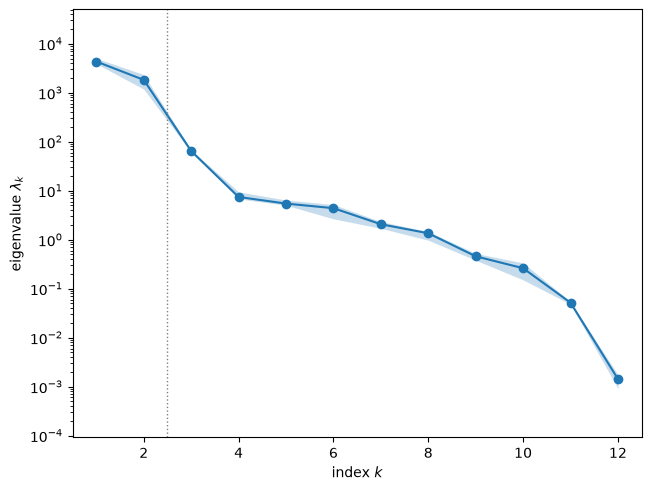

In [5]:
fig, ax = ac.plotting.plot_eigenvalues(sub)
plt.close(fig)
lo, hi = np.percentile(sub.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
print('bootstrap 95% intervals, lambda_1..4:', ', '.join(f'[{a:.3g}, {b:.3g}]' for a, b in zip(lo[:4], hi[:4])))
bl = sub.bootstrap_eigenvalues
q12 = np.percentile(bl[:, 0] / bl[:, 1], [2.5, 97.5])
q23 = np.percentile(bl[:, 1] / bl[:, 2], [2.5, 97.5])
print(f'bootstrap 95% intervals of the ratios: lambda_1/lambda_2 [{q12[0]:.2f}, {q12[1]:.2f}], '
      f'lambda_2/lambda_3 [{q23[0]:.1f}, {q23[1]:.1f}]')
Gn = G[:, 0] * (UPPER - LOWER) / 2                    # normalized gradients of fuel burn
g2 = np.sum(Gn**2, axis=1)                            # their squared norms; sum(g2)/M = trace(C)
order = np.argsort(-g2)
M = len(X)
for k in (1, M // 100, M // 20):
    print(f'the {k} largest samples ({k / M:.2%}) hold {g2[order[:k]].sum() / g2.sum():.1%} of trace(C)')
thin = X[:, 5] < 0.0075
print(f'samples with root thickness thickness_3 < 7.5 mm: {thin.sum()} ({thin.mean():.1%}), '
      f'holding {g2[thin].sum() / g2.sum():.1%} of trace(C); largest sample: row {order[0]}, '
      f'thickness_3 = {1e3 * X[order[0], 5]:.1f} mm')
fig

The first two eigenvalues, $4.34\times10^3$ and $1.83\times10^3$, hold 98.6 % of the sum, and $\lambda_2/\lambda_3 = 28.4$ is the largest ratio among the leading eigenvalues ($\lambda_3/\lambda_4 = 8.7$). The bootstrap 95 % intervals are [3.92e3, 5.05e3] for $\lambda_1$, [1.18e3, 2.35e3] for $\lambda_2$ and [61.3, 68.1] for $\lambda_3$, and [18.4, 36.4] for $\lambda_2/\lambda_3$. These intervals understate the uncertainty, because the gradients are very heavy-tailed. The single largest sample (row 56, root thickness 5.3 mm) holds 6.3 % of trace($\mathbf{C}$), the largest 1 % of the samples hold 31.9 %, and the largest 5 % hold 45.3 %. The 90 samples (4.5 %) with root thickness below 7.5 mm hold 39.7 %. The bootstrap resamples the same few thin-spar points, so it cannot show how much a new draw would change.

### How much do the eigenvalues depend on the draw?

The 2000 rows are independent Monte Carlo samples, so the four blocks of 500 rows are four independent draws of the size of the first release (rows 0–499 are that release), and the two halves are two draws of 1000. For each we print the leading eigenvalues, the ratios, the distance between its two-dimensional subspace and that of all 2000 samples ("dist plane"), the same distance for $\mathbf{w}_1$ alone, and the share of the trace held by its largest 5 % of samples.

In [6]:
def eig_C(rows):
    C = Gn[rows].T @ Gn[rows] / len(rows)
    l, V = np.linalg.eigh(C)
    return l[::-1], V[:, ::-1]


def dist(A, B):                                       # distance between the spans of A and B (2-norm)
    return np.linalg.norm(A @ A.T - B @ B.T, 2)


W = sub.W
print(f"{'rows':>11s} {'lambda_1':>9s} {'lambda_2':>9s} {'lambda_3':>9s} {'l1/l2':>6s} {'l2/l3':>6s}"
      f" {'dist plane':>10s} {'dist w1':>8s} {'top 5% share':>12s}")
blocks = [np.arange(a, a + 500) for a in range(0, M, 500)] + [np.arange(M // 2), np.arange(M // 2, M)]
R12, R23 = [], []
for r in blocks:
    l, V = eig_C(r)
    s5 = np.sort(g2[r])[::-1][:len(r) // 20].sum() / g2[r].sum()
    if len(r) == 500:
        R12.append(l[0] / l[1]); R23.append(l[1] / l[2])
    print(f'{r[0]:5d}:{r[-1] + 1:<5d} {l[0]:9.0f} {l[1]:9.0f} {l[2]:9.1f} {l[0] / l[1]:6.2f} {l[1] / l[2]:6.1f}'
          f' {dist(V[:, :2], W[:, :2]):10.3f} {dist(V[:, :1], W[:, :1]):8.3f} {s5:12.1%}')
print(f'over the {len(R12)} disjoint draws of 500: lambda_1/lambda_2 from {min(R12):.2f} to {max(R12):.2f}, '
      f'lambda_2/lambda_3 from {min(R23):.1f} to {max(R23):.1f}')

       rows  lambda_1  lambda_2  lambda_3  l1/l2  l2/l3 dist plane  dist w1 top 5% share
    0:500        5372      2579      60.9   2.08   42.4      0.012    0.348        58.3%
  500:1000       4130      1576      64.5   2.62   24.5      0.013    0.099        41.2%
 1000:1500       4592      1716      63.7   2.68   27.0      0.014    0.021        44.3%
 1500:2000       3817       912      67.4   4.18   13.5      0.037    0.253        29.0%
    0:1000       4615      2213      62.8   2.09   35.3      0.011    0.139        51.2%
 1000:2000       4151      1368      65.8   3.03   20.8      0.020    0.119        37.9%
over the 4 disjoint draws of 500: lambda_1/lambda_2 from 2.08 to 4.18, lambda_2/lambda_3 from 13.5 to 42.4


Across the four independent draws of 500, $\lambda_2$ ranges from 912 to 2579, $\lambda_1/\lambda_2$ from 2.08 to 4.18 and $\lambda_2/\lambda_3$ from 13.5 to 42.4; the two halves give 35.3 and 20.8. The reviewer's independent 400-sample draw (`default_rng(99)`, not shipped) gave $\lambda_2/\lambda_3 = 8.6$ and $\lambda_1/\lambda_2 = 6.4$. The draw with the largest $\lambda_2$ (rows 0–499) is also the one whose largest 5 % of samples hold the most trace (58.3 %, against 29.0 % for rows 1500–1999): a few thin-root-spar samples set $\lambda_2$. The plane is stable: every block's two-dimensional subspace lies within 0.012–0.037 of the full one. $\mathbf{w}_1$ alone is not (0.021–0.348).

**In plain terms:** the two-dimensional active subspace of fuel burn is well determined, but the eigenvalues, the gap ratios and the split of the plane into $\mathbf{w}_1$ and $\mathbf{w}_2$ are not. The gap below the plane is roughly 10–40 depending on the draw; $\lambda_2/\lambda_3 = 28.4$ is the 2000-sample estimate, not a precise value. The mechanism is physical: the spar (35 % chord) sits behind the aerodynamic center (25 % chord), so lift twists the wing nose-up, and a thin root spar brings the wing close to static divergence. There fuel burn and its gradient grow steeply. At the in-box corner with every thickness 5 mm, $c_r = 1.3$, taper 1.25, $\alpha = 5°$, twist $+1°$ and the minimum $E$ and $G$, the model gives a fuel burn of 843 kg, lift 330 kN and failure 25.8 (`DATA.md`), while the 2000 samples reach at most 261.8 kg.

### Subspace errors

bootstrap mean subspace distance, k = 1..5: [0.097 0.01  0.015 0.209 0.333]


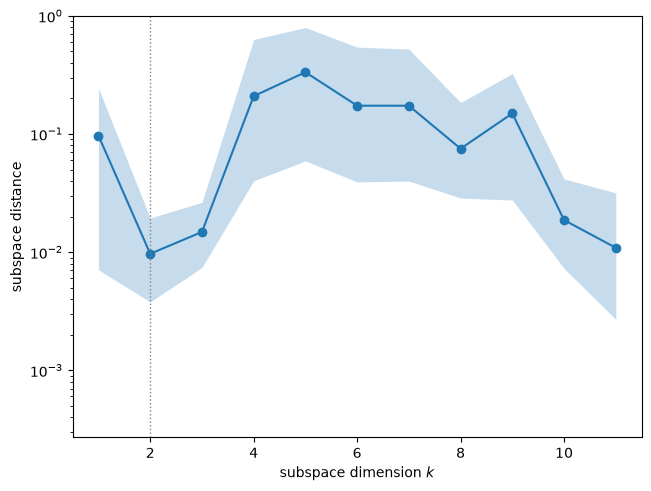

In [7]:
fig, ax = ac.plotting.plot_subspace_errors(sub)
plt.close(fig)
bd = sub.bootstrap_distances.mean(axis=0)
print('bootstrap mean subspace distance, k = 1..5:', np.array2string(bd[:5], precision=3))
fig

The bootstrap mean distance is 0.097 for the one-dimensional subspace, 0.010 for the two-dimensional one, and 0.015 for $k = 3$. The plane is the well-determined object; $\mathbf{w}_1$ on its own is uncertain both under the bootstrap and between independent draws (previous section).

### Eigenvectors

w1: twist_1 +0.196, twist_2 +0.122, twist_3 +0.094, thickness_1 +0.048, thickness_2 +0.005, thickness_3 -0.485, root_chord +0.489, taper_ratio +0.235, alpha +0.632, E -0.016, G -0.063, mrho +0.051
w2: twist_1 +0.130, twist_2 +0.080, twist_3 +0.067, thickness_1 +0.042, thickness_2 +0.026, thickness_3 +0.869, root_chord +0.202, taper_ratio +0.098, alpha +0.402, E +0.021, G +0.003, mrho +0.041
squared length of each input axis inside the plane: twist_1 0.055, twist_2 0.021, twist_3 0.013, thickness_1 0.004, thickness_2 0.001, thickness_3 0.990, root_chord 0.280, taper_ratio 0.065, alpha 0.561, E 0.001, G 0.004, mrho 0.004
weight of (thickness_3, alpha, root_chord) in span(w1, w2): 0.916 of the total 1


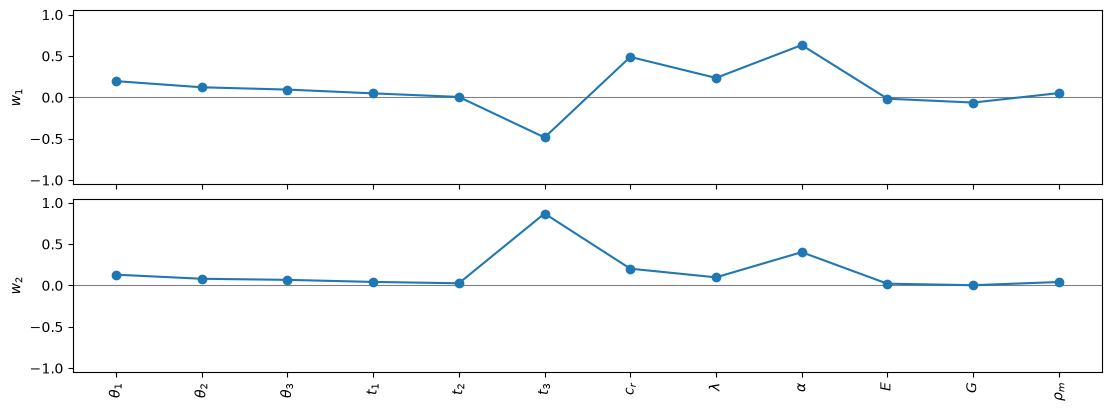

In [8]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, figsize=(11, 4))
plt.close(fig)
for j in range(2):
    print(f'w{j + 1}:', ', '.join(f'{n} {w:+.3f}' for n, w in zip(NAMES, W[:, j])))
P = W[:, :2] @ W[:, :2].T                             # projector onto the plane (independent of the draw-dependent w1, w2)
print('squared length of each input axis inside the plane:', ', '.join(f'{n} {P[k, k]:.3f}' for k, n in enumerate(NAMES)))
print(f'weight of (thickness_3, alpha, root_chord) in span(w1, w2): '
      f'{np.sum(W[[5, 8, 6], :2]**2) / 2:.3f} of the total 1')
fig

Because $\mathbf{w}_1$ and $\mathbf{w}_2$ separately depend on the draw, the plane is better read through its projector: the root-thickness axis lies almost entirely inside it (squared length 0.990), followed by $\alpha$ (0.561) and the root chord (0.280); taper has 0.065 and the first twist control point 0.055. The root spar thickness $t_3$, the angle of attack and the root chord carry 0.916 of the plane's weight. In this draw $\mathbf{w}_1$ is led by $\alpha$ ($+0.632$), $c_r$ ($+0.489$) and $t_3$ ($-0.485$), and $\mathbf{w}_2$ by $t_3$ ($+0.869$) and $\alpha$ ($+0.402$), but how the plane splits into the two vectors changes between draws, so the individual signs and loadings should not be interpreted. The material constants have components of at most 0.063 in magnitude.

### Sufficient summary plots

y1 range [-1.73, 1.56]; corr(fb, y1) = 0.871


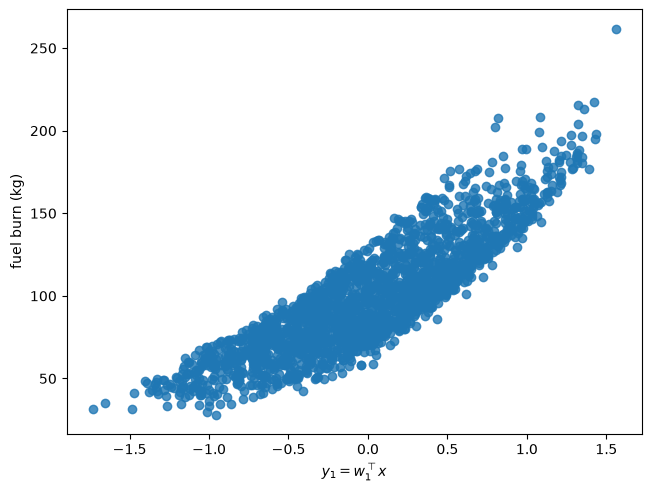

In [9]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=fb, dims=1, qoi_label='fuel burn (kg)')
plt.close(fig)
Y = space.to_normalized(X) @ W[:, :2]
print(f'y1 range [{Y[:, 0].min():.2f}, {Y[:, 0].max():.2f}]; corr(fb, y1) = {np.corrcoef(fb, Y[:, 0])[0, 1]:.3f}')
fig

y2 range [-1.43, 1.45]; corr(fb, y2) = 0.415


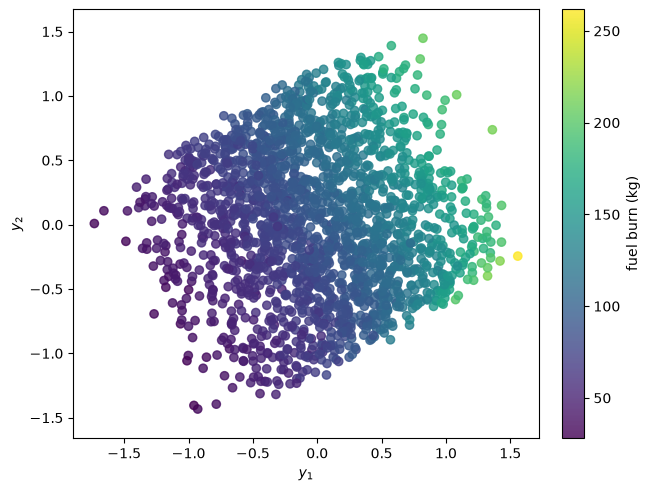

In [10]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=fb, dims=2, qoi_label='fuel burn (kg)')
plt.close(fig)
print(f'y2 range [{Y[:, 1].min():.2f}, {Y[:, 1].max():.2f}]; corr(fb, y2) = {np.corrcoef(fb, Y[:, 1])[0, 1]:.3f}')
fig

Against $y_1$ alone the samples still spread (correlation 0.871). In the $(y_1, y_2)$ plane the color changes smoothly; the correlation with $y_2$ is 0.415. The largest fuel burns, up to 261.8 kg, are the thin-root-spar samples. Note that "fuel burn" here is psdr's output: the Breguet formula evaluated with the CD/CL of the wing at the given $\alpha$, with lift not trimmed to the weight (lift / weight 0.89–7.63 above). It is a function of the drag-to-lift ratio at that angle of attack, not the fuel burn of a mission, and near the divergence corner (843 kg) it reflects a nearly divergent wing.

### Surrogate on the active variables

Polynomials in the active variables, scored by leave-one-out (LOO) $R^2$ on the 2000 samples:

n = 1, degree 2: LOO R^2 = 0.7775
n = 1, degree 3: LOO R^2 = 0.7785
n = 2, degree 2: LOO R^2 = 0.9784
n = 2, degree 3: LOO R^2 = 0.9841


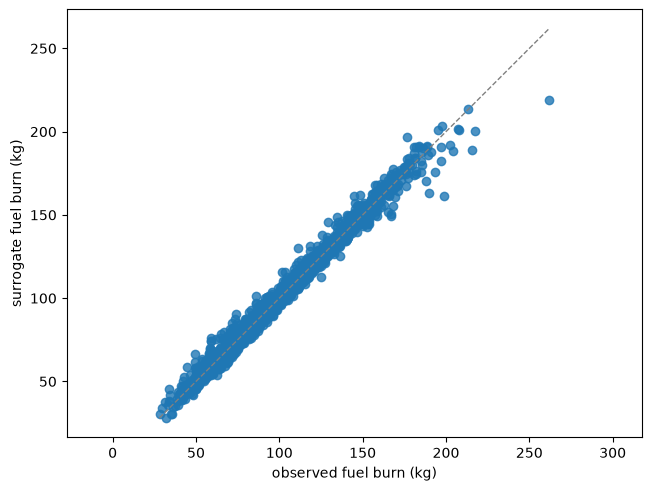

In [11]:
sub1 = ac.active_subspace(space=space, X=X, f=fb, grads=G[:, 0], estimator='as', n=1)
r2 = {}
for d in (2, 3):
    r2[(1, d)] = ac.fit_surrogate(X=X, f=fb, space=space, subspace=sub1, kind='poly', degree=d).loo_r_squared
    r2[(2, d)] = ac.fit_surrogate(X=X, f=fb, space=space, subspace=sub, kind='poly', degree=d).loo_r_squared
for (n, d), v in sorted(r2.items()):
    print(f'n = {n}, degree {d}: LOO R^2 = {v:.4f}')
sur = ac.fit_surrogate(X=X, f=fb, space=space, subspace=sub, kind='poly', degree=3)
fig, ax = ac.plotting.plot_surrogate_fit(sur, X=X, f=fb, qoi_label='fuel burn (kg)')
plt.close(fig)
fig

A cubic in the two active variables has LOO $R^2 = 0.984$ (a quadratic gives 0.978), against 0.7785 for a cubic in $y_1$ alone. Two active variables capture fuel burn on this design space; the remaining 1.6 % of its variance comes from the other ten directions and from curvature that the cubic misses.

### The other outputs

The same estimator applied to psdr's other four outputs, each with its own gradients (no bootstrap):

In [12]:
print(f"{'QoI':16s} {'l1/l2':>8s} {'l2/l3':>8s}  largest |w1| components")
subs = {}
for i, q in enumerate(QOIS):
    s = ac.active_subspace(space=space, X=X, f=F[:, i], grads=G[:, i], estimator='as', n=1)
    subs[i] = s
    l = s.eigenvalues
    top = np.argsort(-np.abs(s.W[:, 0]))[:3]
    print(f'{q:16s} {l[0] / l[1]:8.1f} {l[1] / l[2]:8.1f}  ' + ', '.join(f'{NAMES[k]} {s.W[k, 0]:+.2f}' for k in top))
w_fail = subs[4].W[:, 0]
print(f'|W1(fuel burn)^T w1(failure)| = {np.linalg.norm(W[:, :2].T @ w_fail):.4f}  (1 = inside the fuel-burn subspace)')
r5 = subs[1].eigenvalues[4] / subs[1].eigenvalues[0]
print(f'spar mass: eigenvalues 5..12 / lambda_1 ~ 1e{np.floor(np.log10(r5)):.0f} '
      f'(finite-difference noise in the E, G columns; it depends only on thickness_1..3 and mrho)')

QoI                 l1/l2    l2/l3  largest |w1| components
fuel burn (kg)        2.4     28.4  alpha +0.63, root_chord +0.49, thickness_3 -0.48
spar mass (kg)       26.0      1.1  thickness_1 +0.61, thickness_3 +0.60, mrho +0.45
lift (N)              2.6     27.1  alpha +0.60, thickness_3 -0.58, root_chord +0.47
total mass (kg)       6.7      4.2  thickness_1 +0.55, thickness_3 +0.46, mrho +0.43
failure (KS)         64.5     25.6  thickness_3 +0.99, alpha -0.11, root_chord -0.10
|W1(fuel burn)^T w1(failure)| = 0.9979  (1 = inside the fuel-burn subspace)
spar mass: eigenvalues 5..12 / lambda_1 ~ 1e-9 (finite-difference noise in the E, G columns; it depends only on thickness_1..3 and mrho)


failure: LOO R^2 cubic in w1 0.780, cubic in (w1, w2) 0.943
failure range [-0.69, 6.74]


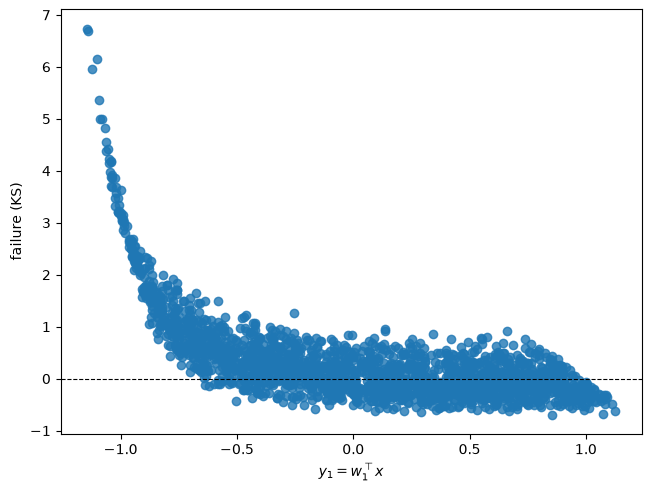

In [13]:
fig, ax = ac.plotting.plot_sufficient_summary(subs[4], X=X, f=fail, dims=1, qoi_label='failure (KS)')
ax.axhline(0, color='k', lw=0.8, ls='--')
plt.close(fig)
y_f = space.to_normalized(X) @ w_fail
sf2 = ac.active_subspace(space=space, X=X, f=fail, grads=G[:, 4], estimator='as', n=2)
print(f'failure: LOO R^2 cubic in w1 {ac.fit_surrogate(X=X, f=fail, space=space, subspace=subs[4], kind="poly", degree=3).loo_r_squared:.3f}, '
      f'cubic in (w1, w2) {ac.fit_surrogate(X=X, f=fail, space=space, subspace=sf2, kind="poly", degree=3).loo_r_squared:.3f}')
print(f'failure range [{fail.min():.2f}, {fail.max():.2f}]')
fig

Failure has the strongest one-dimensional structure: $\lambda_1/\lambda_2 = 64.5$, and its $\mathbf{w}_1$ is almost the root thickness alone ($+0.99$; low $y_1$ means a thin root spar). That direction lies in the fuel-burn plane (projection norm 0.9979). Failure is strongly curved in $y_1$: it reaches 6.74 at the thinnest root spars and is near or below 0 over most of the range. So a cubic in $y_1$ reaches only LOO $R^2 = 0.780$, and a cubic in two active variables reaches 0.943. **This failure output is not psdr's.** With OpenAeroStruct 2.x's load transfer it is lower than with v1's (which psdr used) at every sample, by 0.023–1.86 (median 0.10) over the 2000 samples, and the sign of failure differs at 160 of the 2000 samples (8.0 %) (`DATA.md`). Lift has nearly the same leading eigenvalue ratios as fuel burn (2.6 and 27.1). The spar mass depends only on the three thickness control points and the density, so its eigenvalues 5–12 are about $10^{-9}\lambda_1$, which is finite-difference noise from the $E$ and $G$ columns. Total mass (spar mass plus fuel burn plus $W_0$) has slowly decaying eigenvalues ($\lambda_1/\lambda_2 = 6.7$, $\lambda_2/\lambda_3 = 4.2$). The signs in this table are not oriented.

## Comparison with the paper

The paper is an educational description of the code and has no parameter study, sensitivity analysis or active subspace. The table therefore compares the setup. The numbers in the "psdr" and "v1 load transfer" rows were computed in scratch diagnostics (`DATA.md`, "How these files relate to the paper"), not in this notebook.

In [14]:
rows = [
    ('design variables (Table 1, p. 1826)', 'thickness, twist, alpha, root chord, taper', 'the same, 3 control points each for thickness and twist'),
    ('extra inputs', 'not reported (psdr adds E, G, density)', 'E, G, density, U[0.8, 1.2] x nominal'),
    ('fuel burn model', 'Breguet range equation (Sec. 3.4)', 'Breguet, inviscid CD, untrimmed'),
    ('failure model', 'KS of von Mises stress, Table 1', 'KS (rho = 100), yield 500 MPa / 2.5'),
    ('fuel burn vs psdr, at its 10 test points', 'not reported', 'max rel. diff. 3.5e-3 (DATA.md)'),
    ('failure vs psdr, at its 10 test points', 'not reported', 'differs by -0.07 to -0.14 (load transfer; DATA.md)'),
    ('fuel burn vs v1 load transfer, 2000 samples', 'not reported', 'median 0.14 %, max 13.0 % (DATA.md)'),
    ('failure vs v1 load transfer, 2000 samples', 'not reported', 'lower by 0.023 to 1.86; sign differs at 8.0 % (DATA.md)'),
    ('active subspace dimension of fuel burn', 'not reported', f'n = 2 (override; evg picks {n_lin}, log gap {n_log})'),
    ('lambda_2/lambda_3 of fuel burn', 'not reported', f'{lam[1] / lam[2]:.1f} (M = 2000); {min(R23):.1f} to {max(R23):.1f} over 4 draws of 500'),
    ('LOO R^2, cubic in 2 active variables', 'not reported', f'{r2[(2, 3)]:.3f}'),
]
for q, p, v in rows:
    print(f'{q:44s} | {p:42s} | {v}')

design variables (Table 1, p. 1826)          | thickness, twist, alpha, root chord, taper | the same, 3 control points each for thickness and twist
extra inputs                                 | not reported (psdr adds E, G, density)     | E, G, density, U[0.8, 1.2] x nominal
fuel burn model                              | Breguet range equation (Sec. 3.4)          | Breguet, inviscid CD, untrimmed
failure model                                | KS of von Mises stress, Table 1            | KS (rho = 100), yield 500 MPa / 2.5
fuel burn vs psdr, at its 10 test points     | not reported                               | max rel. diff. 3.5e-3 (DATA.md)
failure vs psdr, at its 10 test points       | not reported                               | differs by -0.07 to -0.14 (load transfer; DATA.md)
fuel burn vs v1 load transfer, 2000 samples  | not reported                               | median 0.14 %, max 13.0 % (DATA.md)
failure vs v1 load transfer, 2000 samples    | not reported                 

## References

- J. P. Jasa, J. T. Hwang, J. R. R. A. Martins, "Open-source coupled aerostructural optimization using Python", *Struct. Multidisc. Optim.* 57(4):1815–1827, 2018. https://doi.org/10.1007/s00158-018-1912-8
- J. S. Gray, J. T. Hwang, J. R. R. A. Martins, K. T. Moore, B. A. Naylor, "OpenMDAO: an open-source framework for multidisciplinary design, analysis, and optimization", *Struct. Multidisc. Optim.* 59(4):1075–1104, 2019. https://doi.org/10.1007/s00158-019-02211-z
- P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, Philadelphia, 2015. https://doi.org/10.1137/1.9781611973860
- P. G. Constantine, E. Dow, Q. Wang, "Active subspace methods in theory and practice: applications to kriging surfaces", *SIAM J. Sci. Comput.* 36(4):A1500–A1524, 2014. https://doi.org/10.1137/130916138
- J. M. Hokanson, psdr (parameter space dimension reduction), test function `OpenAeroStruct`, https://github.com/jeffrey-hokanson/PSDR (software; AGPL-3.0; its settings are described here, not its code)
- OpenAeroStruct 2.12.0, https://github.com/mdolab/OpenAeroStruct (Apache-2.0)

## Acknowledgments

The paper acknowledges support from the National Science Foundation Graduate Research Fellowship under Grant No. DGE-1256260 and from the AFOSR MURI on multi-information sources of multi-physics systems under Award Number FA9550-15-1-0038.

In [15]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 8.7 s
